# Modélisation : prédire la survie des passagers du Titanic

## 1. Contexte et objectif

Nous disposons du jeu de données nettoyé (notebook 02). Nous entraînons trois modèles de classification : la régression logistique, la Random Forest et XGBoost. Nous les comparons ensuite avec la matrice de confusion et les métriques d'évaluation (accuracy, précision, rappel, F1, ROC-AUC).

Règle centrale : tout ce qui est appris à partir des données (médiane, mode, moyenne, encodage) l'est sur le jeu d'entraînement uniquement, pour éviter la fuite de données (data leakage). Nous utilisons donc un `Pipeline` après la séparation.

## 2. Import et lecture du jeu nettoyé

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, ConfusionMatrixDisplay
from xgboost import XGBClassifier

In [2]:
df = pd.read_csv("../data/titanic_nettoye.csv")
print(df.shape)
print(df.isna().sum()[lambda s: s > 0])
df.head()

(891, 11)
Age         177
Embarked      2
dtype: int64


,PassengerId,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked,Titre,Cabine_Renseignee
0,1,0,3,male,22.0,1,0,7.2500,S,Mr,0
1,2,1,1,female,38.0,1,0,71.2833,C,Mrs,1
2,3,1,3,female,26.0,0,0,7.9250,S,Miss,0
3,4,1,1,female,35.0,1,0,53.1000,S,Mrs,1
4,5,0,3,male,35.0,0,0,8.0500,S,Mr,0


Nous constatons que le jeu compte 891 lignes et 11 colonnes. `Age` et `Embarked` contiennent encore des valeurs manquantes : c'est voulu, nous les imputerons dans le pipeline avec des valeurs calculées sur le train.

## 3. Séparation entraînement / validation

Nous retirons `PassengerId` (un identifiant n'a aucun pouvoir explicatif), puis nous séparons les données en 80 % pour l'entraînement et 20 % pour la validation. `stratify=y` conserve la même proportion de survivants dans les deux jeux, et `random_state=42` rend le résultat reproductible.

In [3]:
X = df.drop(columns=["Survived", "PassengerId"])
y = df["Survived"]
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
print(X_train.shape, X_val.shape)
print(y_train.mean().round(3), y_val.mean().round(3))

(712, 9) (179, 9)
0.383 0.385


Nous constatons que le train compte 712 passagers et la validation 179. La part de survivants est quasi identique (0,383 contre 0,385) : la stratification a bien joué son rôle. Avec 179 passagers en validation, un passager de plus ou de moins bien classé change l'accuracy d'environ 0,6 point : nous garderons cela en tête pour comparer les modèles.

## 4. Préprocessing dans un pipeline

Nous traitons les colonnes selon leur type :
- numériques (`Age`, `Fare`, `SibSp`, `Parch`, `Pclass`) : imputation par la médiane puis standardisation (utile à la régression logistique, sans effet sur les arbres) ;
- catégorielles (`Sex`, `Embarked`, `Titre`) : imputation par le mode puis encodage one-hot ;
- binaire (`Cabine_Renseignee`) : conservée telle quelle.

Le `ColumnTransformer` apprend ces valeurs (`fit`) sur le train, puis les applique (`transform`) à la validation.

In [4]:
numeriques = ["Age", "Fare", "SibSp", "Parch", "Pclass"]
categorielles = ["Sex", "Embarked", "Titre"]
binaires = ["Cabine_Renseignee"]

def creer_preprocesseur():
    return ColumnTransformer([
        ("num", Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())]), numeriques),
        ("cat", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")), ("ohe", OneHotEncoder(handle_unknown="ignore"))]), categorielles),
        ("bin", "passthrough", binaires)])

## 5. Modèle de référence

Avant de juger nos modèles, nous mesurons un modèle qui prédit toujours la classe majoritaire (« décédé »). C'est le seuil minimal à dépasser.

In [5]:
base = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
acc_base = accuracy_score(y_val, base.predict(X_val))
print(round(acc_base, 3))

0.615


Nous constatons qu'un modèle sans aucune intelligence atteint 0,615 d'accuracy. Un modèle n'a d'intérêt que s'il fait nettement mieux, et la précision comme le rappel de ce modèle de référence sont nuls pour la classe « survivant ».

## 6. Entraînement des trois modèles

Nous définissons les trois modèles avec des hyperparamètres simples (aucun réglage poussé à ce stade). Chaque modèle est placé dans un `Pipeline` avec son préprocesseur, ce qui garantit que l'imputation et l'encodage sont appris sur le train seulement.

Pour chaque modèle, nous calculons :
- les métriques sur le jeu de validation ;
- une validation croisée à 5 plis sur le train, plus robuste qu'un seul découpage.

In [6]:
modeles = {
    "Régression logistique": LogisticRegression(max_iter=1000),
    "Random Forest": RandomForestClassifier(n_estimators=300, random_state=42),
    "XGBoost": XGBClassifier(n_estimators=200, learning_rate=0.05, max_depth=3, eval_metric="logloss", random_state=42),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
resultats, matrices, pipelines = [], {}, {}

for nom, modele in modeles.items():
    pipe = Pipeline([("preprocesseur", creer_preprocesseur()), ("modele", modele)])
    pipe.fit(X_train, y_train)
    y_pred = pipe.predict(X_val)
    y_proba = pipe.predict_proba(X_val)[:, 1]
    scores_cv = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="accuracy")
    pipelines[nom] = pipe
    matrices[nom] = confusion_matrix(y_val, y_pred)
    resultats.append({
        "Modèle": nom,
        "Accuracy": accuracy_score(y_val, y_pred),
        "Précision": precision_score(y_val, y_pred),
        "Rappel": recall_score(y_val, y_pred),
        "F1": f1_score(y_val, y_pred),
        "ROC-AUC": roc_auc_score(y_val, y_proba),
        "Accuracy CV (moyenne)": scores_cv.mean(),
        "Accuracy CV (écart type)": scores_cv.std(),
    })

tableau = pd.DataFrame(resultats).set_index("Modèle").round(3)
tableau

,Accuracy,Précision,Rappel,F1,ROC-AUC,Accuracy CV (moyenne),Accuracy CV (écart type)
Modèle,,,,,,,
Régression logistique,0.838,0.794,0.783,0.788,0.873,0.824,0.026
Random Forest,0.804,0.758,0.725,0.741,0.833,0.819,0.012
XGBoost,0.788,0.763,0.652,0.703,0.849,0.824,0.032


Nous constatons que :
- Régression logistique : accuracy 0,838, précision 0,794, rappel 0,783, F1 0,788, ROC-AUC 0,873, accuracy en validation croisée 0,824 (écart type 0,026).
- Random Forest : accuracy 0,804, précision 0,758, rappel 0,725, F1 0,741, ROC-AUC 0,833, accuracy en validation croisée 0,819 (écart type 0,012).
- XGBoost : accuracy 0,788, précision 0,763, rappel 0,652, F1 0,703, ROC-AUC 0,849, accuracy en validation croisée 0,824 (écart type 0,032).

Les trois modèles dépassent nettement le modèle de référence (0,615). L'écart d'accuracy entre le meilleur et le moins bon est de 0,050, soit environ 9 passagers sur 179 : sur ce seul découpage, cet écart peut venir du hasard de la répartition. La validation croisée, plus stable, donne un second avis : les trois modèles y sont quasi à égalité (0,819 à 0,824), nous ne retenons donc pas de gagnant net.

## 7. Matrices de confusion

La matrice de confusion montre où chaque modèle se trompe. Les lignes sont les valeurs réelles, les colonnes les prédictions : en haut à gauche les vrais négatifs, en bas à droite les vrais positifs, en haut à droite les faux positifs (prédit survivant à tort) et en bas à gauche les faux négatifs (survivant manqué).

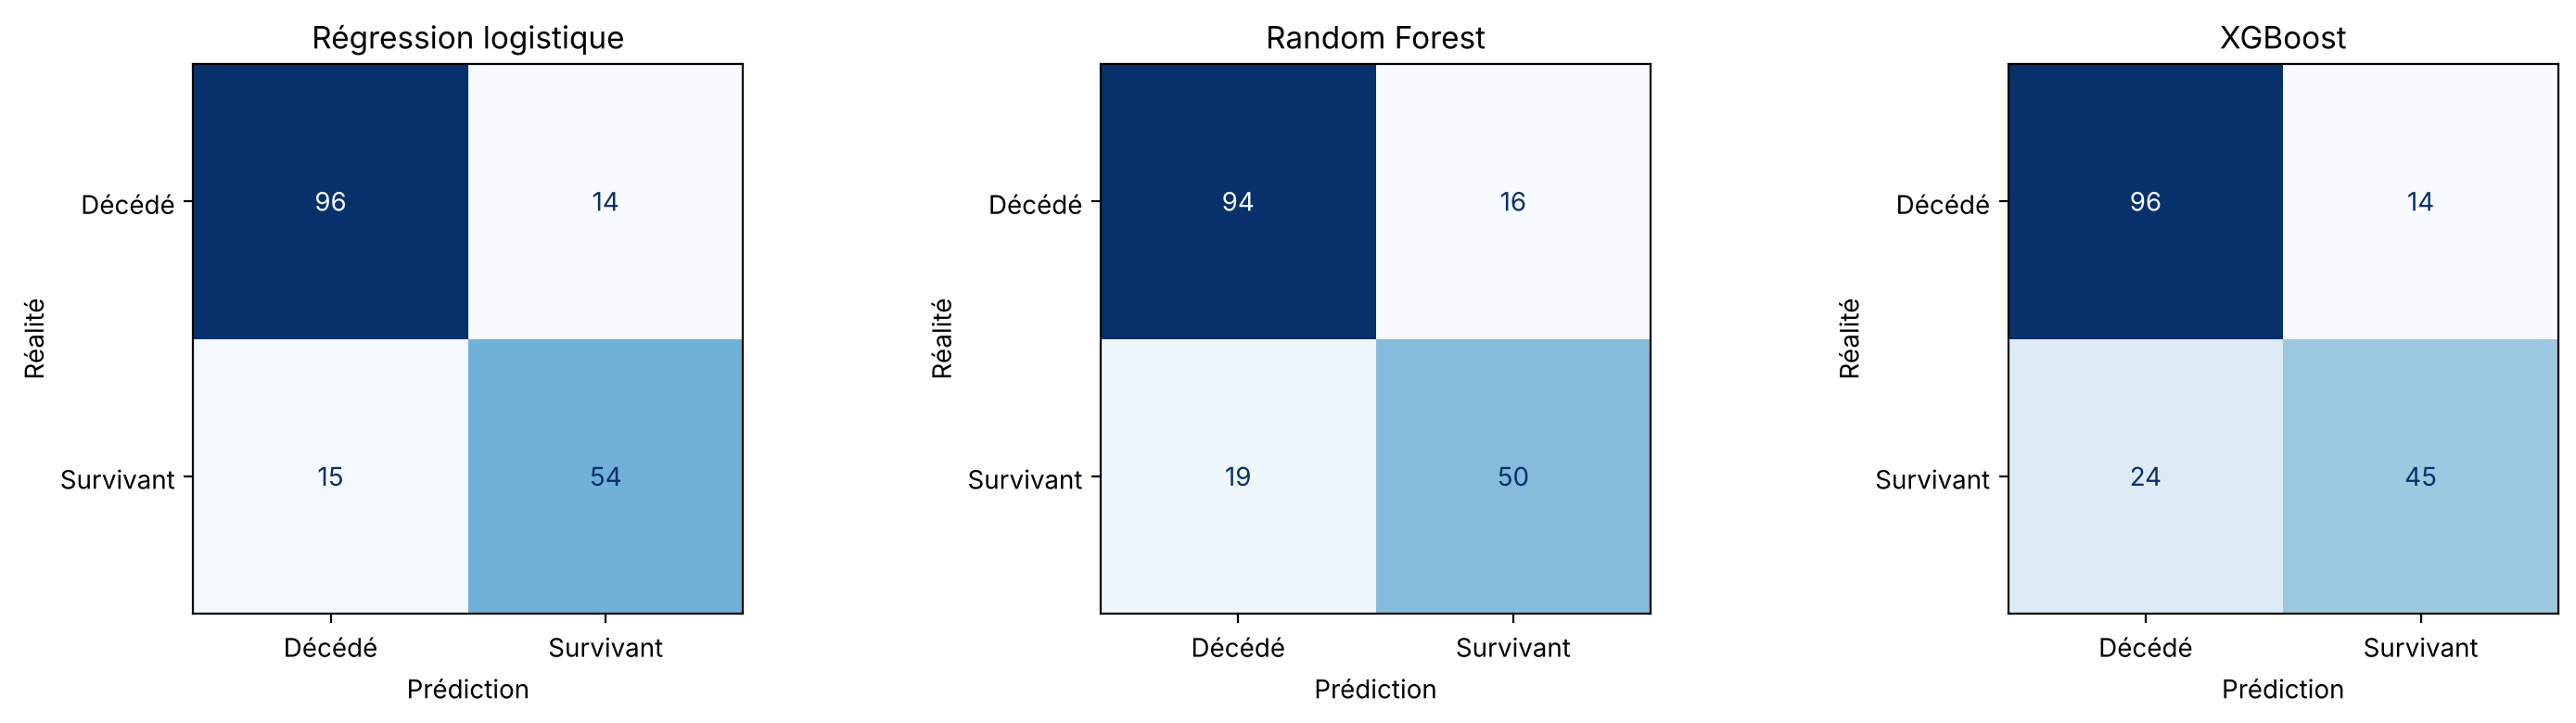

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (nom, cm) in zip(axes, matrices.items()):
    ConfusionMatrixDisplay(cm, display_labels=["Décédé", "Survivant"]).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(nom)
    ax.set_xlabel("Prédiction")
    ax.set_ylabel("Réalité")
plt.tight_layout()
plt.show()

Nous constatons que :
- Régression logistique : 54 survivants bien identifiés, 15 manqués, 14 fausses alertes et 96 décédés bien identifiés.
- Random Forest : 50 survivants bien identifiés, 19 manqués, 16 fausses alertes et 94 décédés bien identifiés.
- XGBoost : 45 survivants bien identifiés, 24 manqués, 14 fausses alertes et 96 décédés bien identifiés.

Nous comparons surtout les faux négatifs (survivants non détectés), qui sont liés au rappel, et les faux positifs, qui sont liés à la précision. Ici, aucune erreur n'est plus grave que l'autre : nous prenons le F1 comme compromis.

## 8. Variables les plus importantes

Pour comprendre ce que les modèles ont appris, nous regardons l'importance des variables de la Random Forest (le calcul se base sur le gain de pureté des arbres).

In [8]:
rf = pipelines["Random Forest"]
noms = rf.named_steps["preprocesseur"].get_feature_names_out()
importances = pd.Series(rf.named_steps["modele"].feature_importances_, index=noms).sort_values(ascending=False)
importances.head(8).round(3)

num__Fare                 0.227
num__Age                  0.206
cat__Titre_Mr             0.099
cat__Sex_female           0.096
cat__Sex_male             0.087
num__Pclass               0.071
num__SibSp                0.049
bin__Cabine_Renseignee    0.044
dtype: float64

Nous constatons que les cinq variables les plus importantes sont `Fare` (0,227), `Age` (0,206), `Titre_Mr` (0,099), `Sex_female` (0,096), `Sex_male` (0,087). Ce classement est cohérent avec l'exploration (notebook 01) : le sexe (et le titre, qui en dérive), la classe et le prix du billet dominent. Les variables `Titre` et `Sex` portent en partie la même information : l'importance se répartit entre elles, ce qui peut sous-estimer chacune.

## 9. Conclusion

Sur notre jeu de validation, le meilleur F1 est obtenu par **Régression logistique** (0,788), mais la validation croisée place les trois modèles à égalité : nous ne pouvons pas affirmer qu'il est réellement meilleur. Les trois approches dépassent clairement le modèle de référence (0,615).

Limites et suites possibles :
- une seule séparation train / validation sur un petit effectif : nous nous appuyons aussi sur la validation croisée ;
- hyperparamètres non optimisés : nous pouvons tester `GridSearchCV` sur le modèle retenu ;
- le fichier `test.csv` de Kaggle devra subir le même nettoyage fixe, puis le pipeline entraîné, pour produire la soumission.